# Real mid-infrared SNSPD return-delay imaging

## 1. Problem

Recover a spatial map of relative strongest-return delay from real mid-infrared photon-arrival histograms despite instrument timing blur, low photon counts and competing echoes.

This review actively reconstructs the complete **native50×50×10000** photon-arrival measurement of a foil-wrapped Nobel chocolate medal. Hardware/data: Kuznesof etal., Optics Express2025, DOI10.1364/OE.576861, Glasgow data DOI10.5525/gla.researchdata.2070(CC BY4.0). Algorithm: Gutierrez-Barragan etal., CVPR2022, **published Full-Resolution Histogram matched-filter baseline**, from its original official implementation. This is a disclosed cross-source binding; the SNSPD hardware is not the CVPR SPAD camera, and the selected method is not the compressed-camera main proposal.


## 2. Data

These are existing **real SNSPD measurements** and a separately supplied instrument-response measurement. The scan is retained at its native50 by50 spatial sampling with all10000 temporal bins. No synthetic observation, target-dependent IRF, hidden surface mask or denoised histogram is supplied.

| Key | Shape | Dtype | Description |
|---|---|---|---|
| photon_counts | (1,50,50,10000) | uint32 | Detected photons per1ps bin; axes batch,scan_row,scan_column,time. |
| instrument_response | (1,10000) | float64 | Independently measured3500nm instrument-response photon counts per1ps bin, raw electronic time origin; normalize to unit sum and move its maximum to0 for the declared template. |

**Acquisition metadata**

| Parameter | Value | Unit | Meaning |
|---|---|---|---|
| Wavelength | 3500 | nm | Mid-infrared illumination. |
| Detector | tungsten-silicide superconducting nanowire | type | SNSPD, not a SPAD array. |
| Integration | 20 | s/pixel | Native scanned measurement dwell. |
| Bin width delta t | 1 | ps | Uniform histogram and IRF temporal sampling. |
| Bins N | 10000 | bins | All supplied bins retained. |
| Timestamp window | 10 | ns | Computational circular window; no independent repetition-period calibration supplied. |
| Time-bin centers | i times1ps, i=0..9999 | ps | Supplied IRF time column. |
| Light speed c0 | 299792458 | m/s | Used for relative round-trip delay conversion. |
| Reference | row0,column0 | pixel | Fixed public observation-defined distance gauge. |
| Instrument timing jitter | 46.14 | ps | Reported full-system timing jitter; not a recovered depth error. |
| Dark-count rate | approximately50 | counts/s | Reported operating condition, not an exact per-pixel background calibration. |
| Target diameter | 55 | mm | Physical medal size; scan-coordinate pitch is not independently calibrated here. |
| Target stand-off from mirror | 100 | mm | Experimental context; electronic delays prevent using this as absolute per-pixel range zero. |
| Entering optical power | 2 | mW | Reported transceiver input average power. |
| Spatial sampling | 50 rows by50 columns | pixels | Retain source file row,column ordering; display in pixel coordinates. |
| Boundary | circular temporal template shifts, no spatial boundary model | convention | No range gate or spatial regularity assumption. |


The output is signed relative apparent depth d=(s-s[0,0])c delta_t/2 in millimeters, c=299792458m/s and delta_t=1ps. One bin corresponds to0.149896229mm. The reference is fixed pixel(0,0), not an independent absolute range calibration. Retain the ordinary signed bin difference rather than a shortest-period unwrap. No physical surface truth or guaranteed submillimeter accuracy is available.


## 3. Physics

The observations are a native50 by50 scan of a foil-wrapped Nobel chocolate medal measured using a3500nm superconducting nanowire single-photon detector (**SNSPD**). Estimate the strongest IRF-matched return at every pixel using the complete10000-bin histogram. Do not replace this with an assumed near-range gate or a smooth surface. A useful single-return measurement model is


$$
Y_{rci}\sim\operatorname{Poisson}\left(A_{rc}\,h[(i-s_{rc})\bmod N]+b_{rc}\right),\qquad d_{rc}=\frac{c_0\Delta t}{2}\left(s_{rc}-s_{00}\right).
$$


Y is the measured integer photon count, r/c are scan row/column indices, i is temporal bin index, N=10000, h is the nonnegative unit-sum instrument-response template with its maximum shifted to bin0, s is the integer matched-return bin, A is nonnegative signal photon count, b is nonnegative uniform background count per bin, c0 is light speed and delta t is bin width. The circular shift is the selected full-window decoder's computational boundary convention; it is not evidence that the laser repetition period equals the supplied window. Real pixels may violate the single-return model through multiple echoes. The histogram maximum itself need not equal the blurred pulse's best matched delay.


The independent3500nm IRF is a separate instrument measurement, not extracted from the hidden coin surface. Its raw maximum is bin6873. Rolling that peak to0 gives a unit-sum temporal template h. Each scan pixel has a1ps-bin histogram y. A simple forward model is Poisson(A roll(h,s)+b), where s is the integer temporal delay, A the signal photon count and b uniform background counts/bin. The model can fail in the presence of multiple returns, which remain visible and unmasked.


## 4. Method

### Explicit matched filter and physical limits

Define z(a)=(a-mean(a))/(norm(a-mean(a))+1e-8). Compute correlation C[s]=real(IFFT(conj(FFT(z(h)))*FFT(z(y)))) at every one of10000lags and choose its first maximum. Equivalently, C[s]=sum_i z(h)[i] z(y)[(i+s)mod10000]. Mean subtraction rejects a constant background and normalization removes amplitude dependence. Original reconstruction rolls h by this lag then reads its maximum; with peak-zero h this is exactly the selected lag. The original complete10000-bin constructor and2500 decodes were run independently before extraction.

The computational boundary is circular over the supplied10ns array. It is not a claim that the laser period was independently measured to be10ns. The exact known-shift tests span both edges, and direct lag sums check the FFT sign. The raw electronics zero is not an absolute optical path calibration.

All pixels and bins are evaluated; no count mask, range gate, clipping or spatial smoothing enters the inverse. A literature discussion of33000counts for600um timing precision is contextual and not an accuracy statement for all pixels. Even bright pixels can exhibit a stronger competing early return. The full-window result is retained, together with explicit display-only saturation and full-scale panels.


## 5. Results

The preserved code below contains the active reconstruction and comparison path. Its saved outputs are retained from the earlier execution. This documentation edit does not rerun that path; displayed measurements remain evidence of the stored execution rather than a new numerical run.


In [1]:
%matplotlib inline
from pathlib import Path
import os,sys,json,time
task=Path.cwd()
if not (task/'src').is_dir(): task=task.parent
if not (task/'src').is_dir(): raise RuntimeError('Execute in the task or notebooks directory')
sys.path.insert(0,str(task))
import numpy as np,matplotlib.pyplot as plt
from src.visualization import review
print('Kernel executable:',sys.executable,'NumPy:',np.__version__)
figure_dir=Path(os.environ.get('IMAGING_FIGURE_DIR',str(task/'output/review_figures')))


Kernel executable: D:\yan1\agent\AutoSkill\imaging-101-maintainer\research-runtime\Scripts\python.exe NumPy: 2.4.6


In [2]:
start=time.perf_counter()
figures,measurements=review(task,figure_dir)
print('Complete fresh review seconds:',time.perf_counter()-start)
print(json.dumps(measurements,indent=2))


Complete fresh review seconds: 14.573285899998154
{
  "fresh_seconds": 0.846119900001213,
  "judge": {
    "status": "pass",
    "passed": true,
    "metrics": {
      "max_abs_bin_error": 0.0,
      "mean_abs_bin_error": 0.0,
      "mean_correlation_regret": 0.0
    },
    "thresholds": {
      "max_abs_bin_error": {
        "comparison": "<=",
        "boundary": 1e-06
      },
      "mean_abs_bin_error": {
        "comparison": "<=",
        "boundary": 1e-07
      },
      "mean_correlation_regret": {
        "comparison": "<=",
        "boundary": 0.0001
      }
    },
    "errors": []
  },
  "reference_pixel_photons": 5142,
  "count_below33000": 1408,
  "number_pixels": 2500,
  "depth_mm_range": [
    -409.81629008600004,
    1084.499216815
  ],
  "not_ground_truth": "All differences below compare methods/resolution, not measured physical range accuracy.",
  "actual_histogram_examples": [
    {
      "row": 0,
      "column": 0,
      "photons": 5142,
      "matched_bin": 2764,
 

### Figure 1

Measured photon counts and independent calibration; all2500 points remain in the inverse. The paper count threshold is a visual contextual marker only.


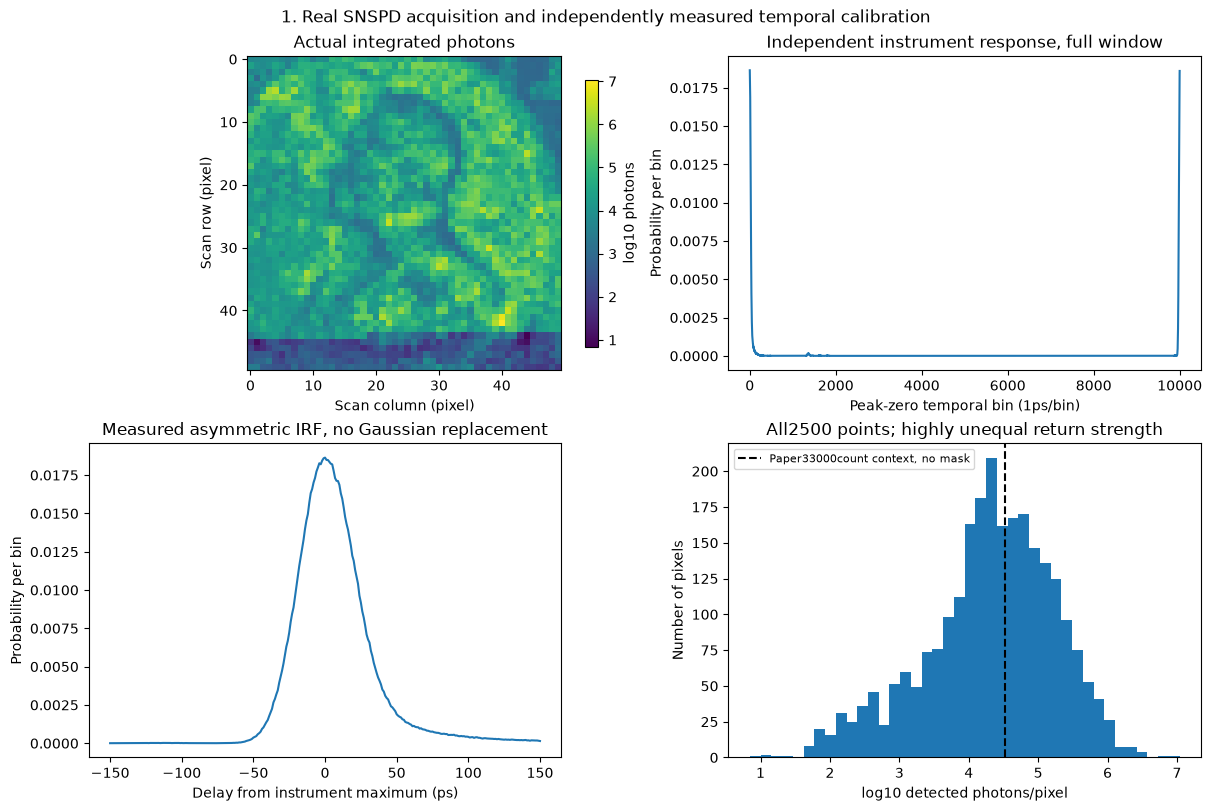

In [3]:
display(figures[0])
plt.close(figures[0])

### Figure 2

Original-source and fresh full-window outputs. The separately labeled3.5..6mm panel saturates only its displayed colors to reveal the dominant cluster; the submitted arrays and evaluator preserve the entire signed range. There is no ground-truth depth map.


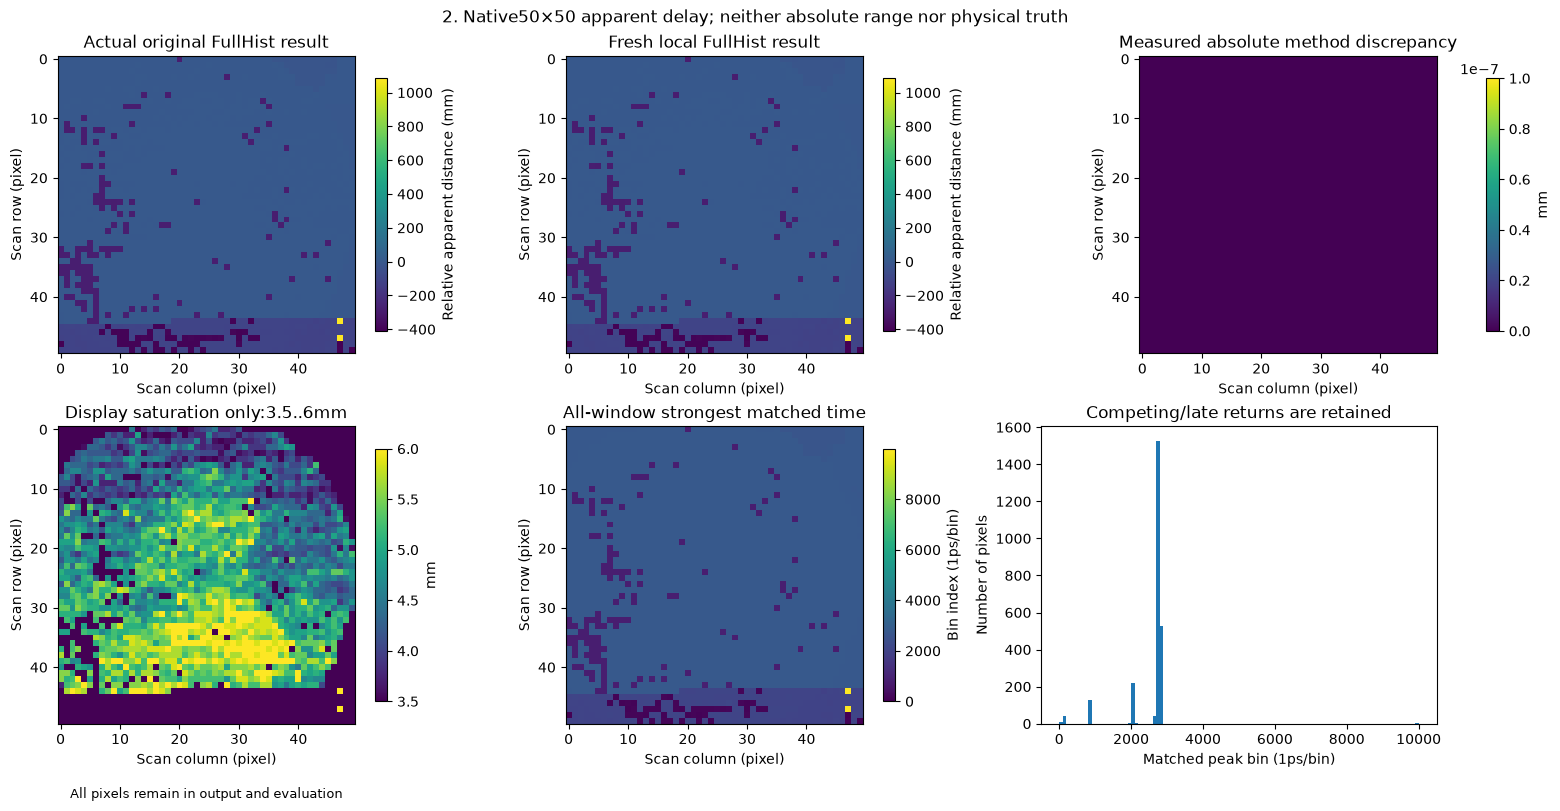

In [4]:
display(figures[1])
plt.close(figures[1])

### Figure 3

Actual raw histories at the fixed reference, a competing-return pixel and the darkest/brightest measured points. The fitted nonnegative single-pulse+background curves are diagnostics only; they do not modify matched peaks.


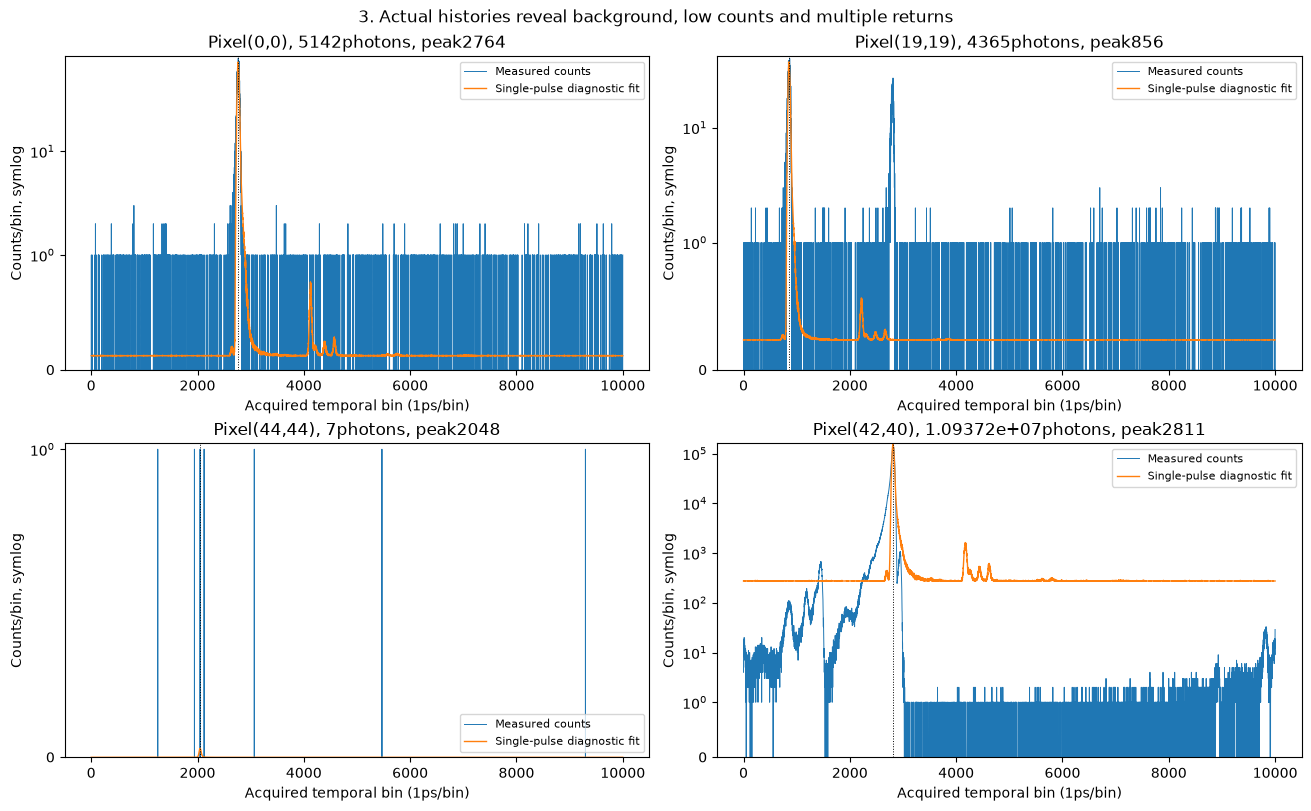

In [5]:
display(figures[2])
plt.close(figures[2])

### Figure 4

Full-lag correlation, independent direct dot sums, actual counts/confidence scatter and comparison to raw histogram maxima. Confidence alone cannot identify which optical return belongs to the medal.


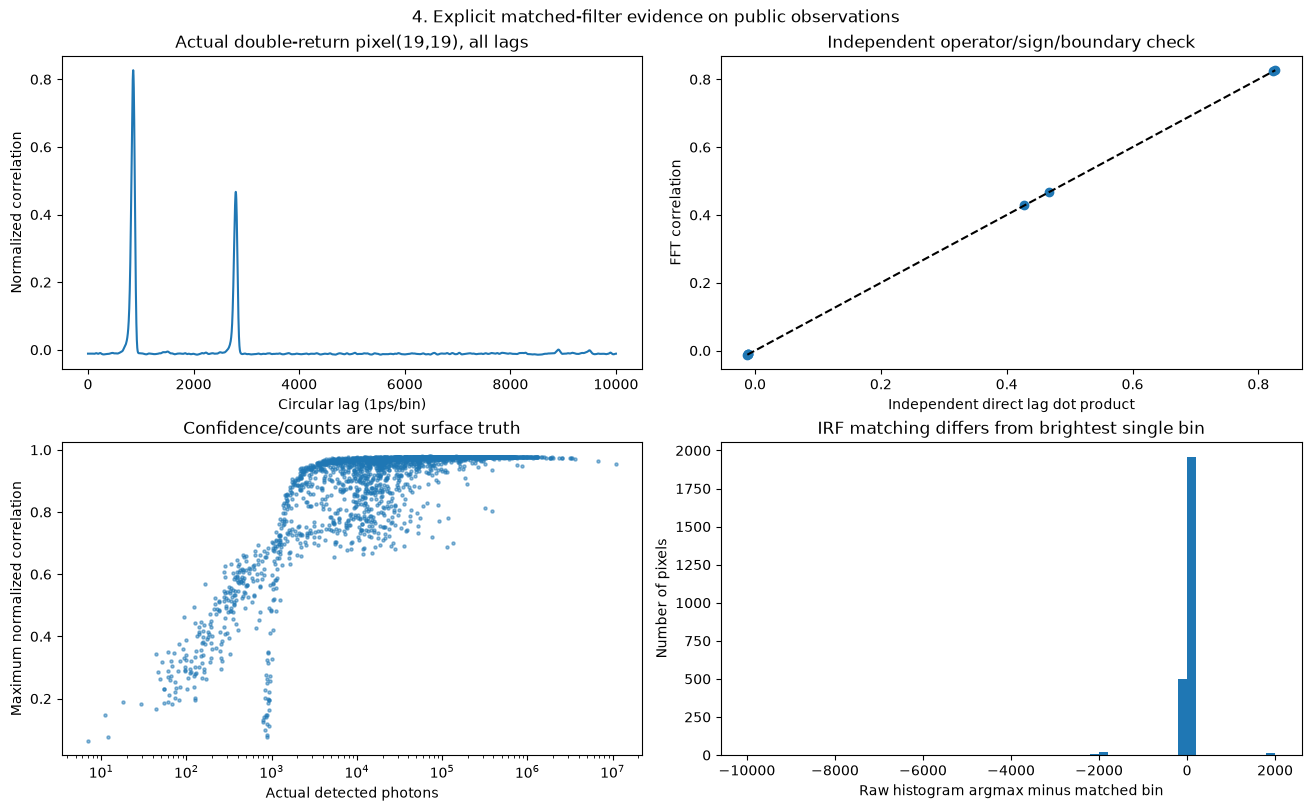

In [6]:
display(figures[3])
plt.close(figures[3])

### Figure 5

Deterministic aggregation of the same real histograms into2/4/10ps bins with correspondingly aggregated calibration. These are post-acquisition numerical comparisons, not measurements from new compressed hardware. All reported differences use the native standard method as reference, never independent surface truth.


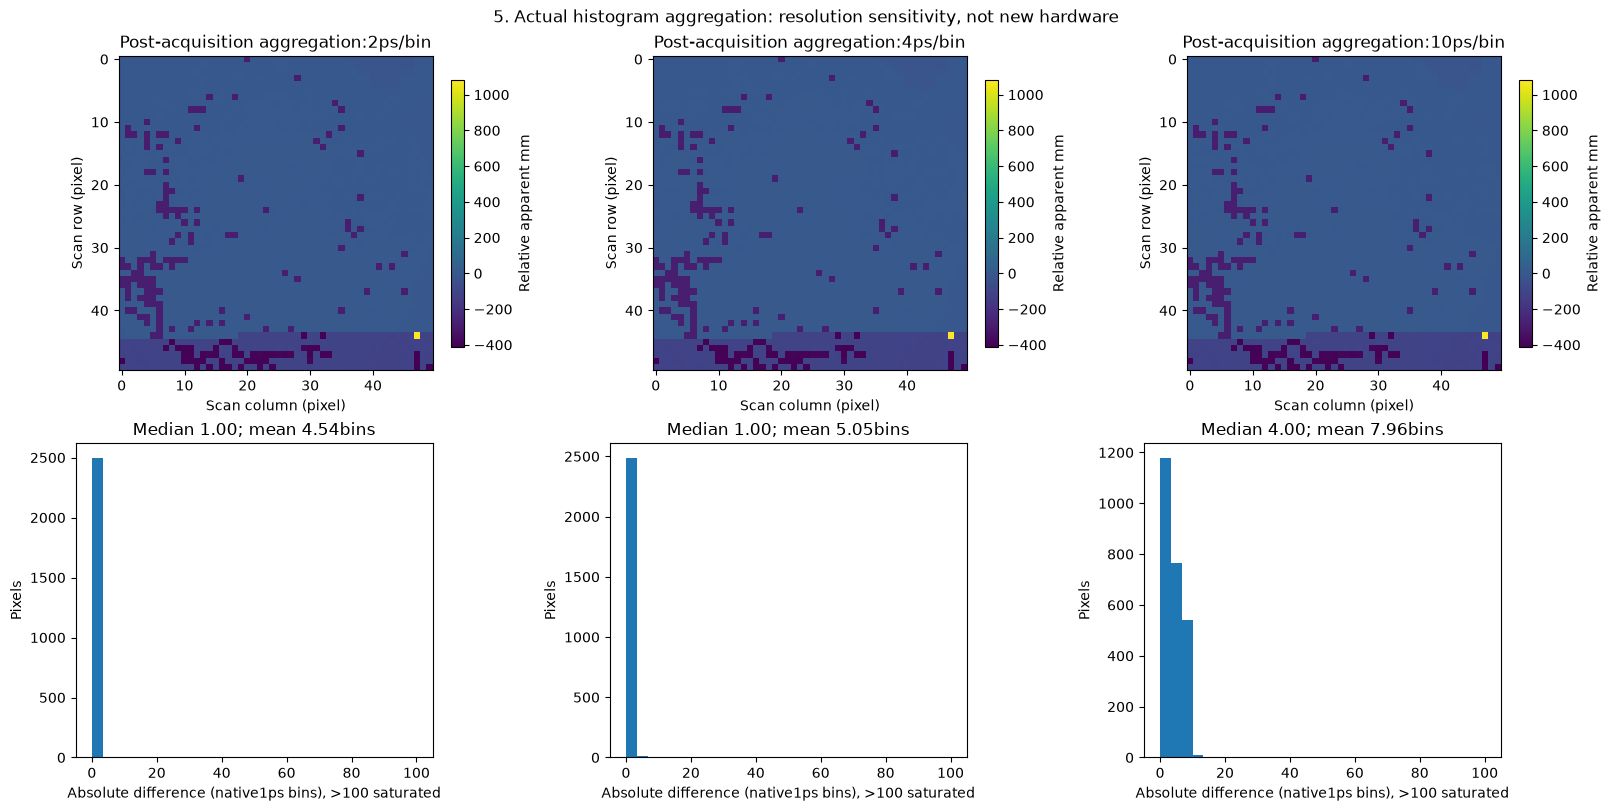

In [7]:
display(figures[4])
plt.close(figures[4])

## 6. Conclusion

### Evaluation and conclusion

The independent evaluator checks maximum and mean absolute delay differences in native timing-bin units, and public-observation correlation regret. Every pixel is required with a fixed zero at the corner; no fitted offset or hidden evaluation mask is allowed. Original and fresh results are method estimates, not truth. Their agreement verifies extraction of the selected published baseline, while the raw multipath/low-count histories explain why such agreement does not establish physical surface accuracy. Exact exported arrays and metrics accompany all five PNG/SVG/PDF groups.
Nonzero max1e-6bin and mean1e-7bin comparison tolerances cover measured floating conversion order only; complete original and fresh integer peaks are exact. Independent Decimal rational conversion over every acquired lag measured the roundoff bound. The CVPR helper approximates light speed as3e8m/s; this task explicitly uses the exact public SI constant299792458m/s for both original-peak and fresh-peak relative millimeters. Peak reconstruction is unchanged; this is a disclosed unit adaptation.

The matched-filter lag is relative to corner pixel (0,0), with ordinary signed bin difference. Full-window circular correlation retains multipath and low-count failures. Exact integer-peak parity and floating conversion tolerances do not establish submillimetre physical accuracy of the medal surface.
